# Analysis of trajectories

In [ ]:
import json
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import shutil
from matplotlib import pyplot as plt

while os.path.split(os.getcwd())[-1] != 'calvados-slim':
    os.chdir('..')

from src import curation, utils, constants, visualisation
from src.analysis import slim

## Processing

In [2]:
# Looping over scans
results = []
reuse = True

# Looping over systems
scan_dir = 'sim/scan'
for system in os.listdir(scan_dir):
    system_dir = os.path.join(scan_dir, system)

    # Looping over scans
    for k_dir in tqdm(sorted(os.listdir(system_dir)), desc=f"Analysing '{system}' trajectories"):

        # Determining k-value
        k = float(k_dir.split('=')[-1])
        kd_csv = os.path.join(system_dir, k_dir, 'kd.csv')
        specific_interactions_txt = os.path.join(system_dir, k_dir, 'specific_interactions.txt')

        # Loading precalculated
        if os.path.exists(kd_csv) and reuse:
            Kd, Kd_m1sem, Kd_p1sem = pd.read_csv(kd_csv).values[0]
        
        else:
            try:
                # Determining state of trajectory
                traj_dcd = os.path.join(system_dir, k_dir, f'{system}.dcd')
                running_scan =  utils.get_dcd_frame_count(traj_dcd) // 10000 != 0

                # Calculating Kds with blocking SEM estimate
                Kd, Kd_m1sem, Kd_p1sem = slim.TwoChain.get_kd_sem(
                    top_pdb = os.path.join(system_dir, k_dir, 'top.pdb'),
                    traj_dcd = traj_dcd,
                    specific_interactions_txt = os.path.join(system_dir, k_dir, 'specific_interactions.txt'),   
                    csv_path = kd_csv if not running_scan else None
                )
            
            # Simulation not run yet
            except OSError:
                Kd, Kd_m1sem, Kd_p1sem = (np.NaN, np.NaN, np.NaN)

        # Calculating number of contacts
        specific_interactions = utils.parse_specific_interactions(specific_interactions_txt)
        N_C = len(specific_interactions)
        L_D = specific_interactions['Donor residue'].max() - specific_interactions['Donor residue'].min() + 1

        # Appending results
        results.append({
            "System": system,
            "k": k,
            "N_C": N_C,
            "L_D": L_D,
            "rho_C": N_C/L_D,
            "Kd": Kd,
            "Kd-1SEM": Kd_m1sem,
            "Kd+1SEM": Kd_p1sem,
            "dG": slim.dG(Kd),
            "dG-1SEM": slim.dG(Kd_m1sem),
            "dG+1SEM": slim.dG(Kd_p1sem),
        })

results = pd.DataFrame(results)


Analysing 'mdm2-p73' trajectories: 100%|██████████| 24/24 [00:00<00:00, 52.47it/s]


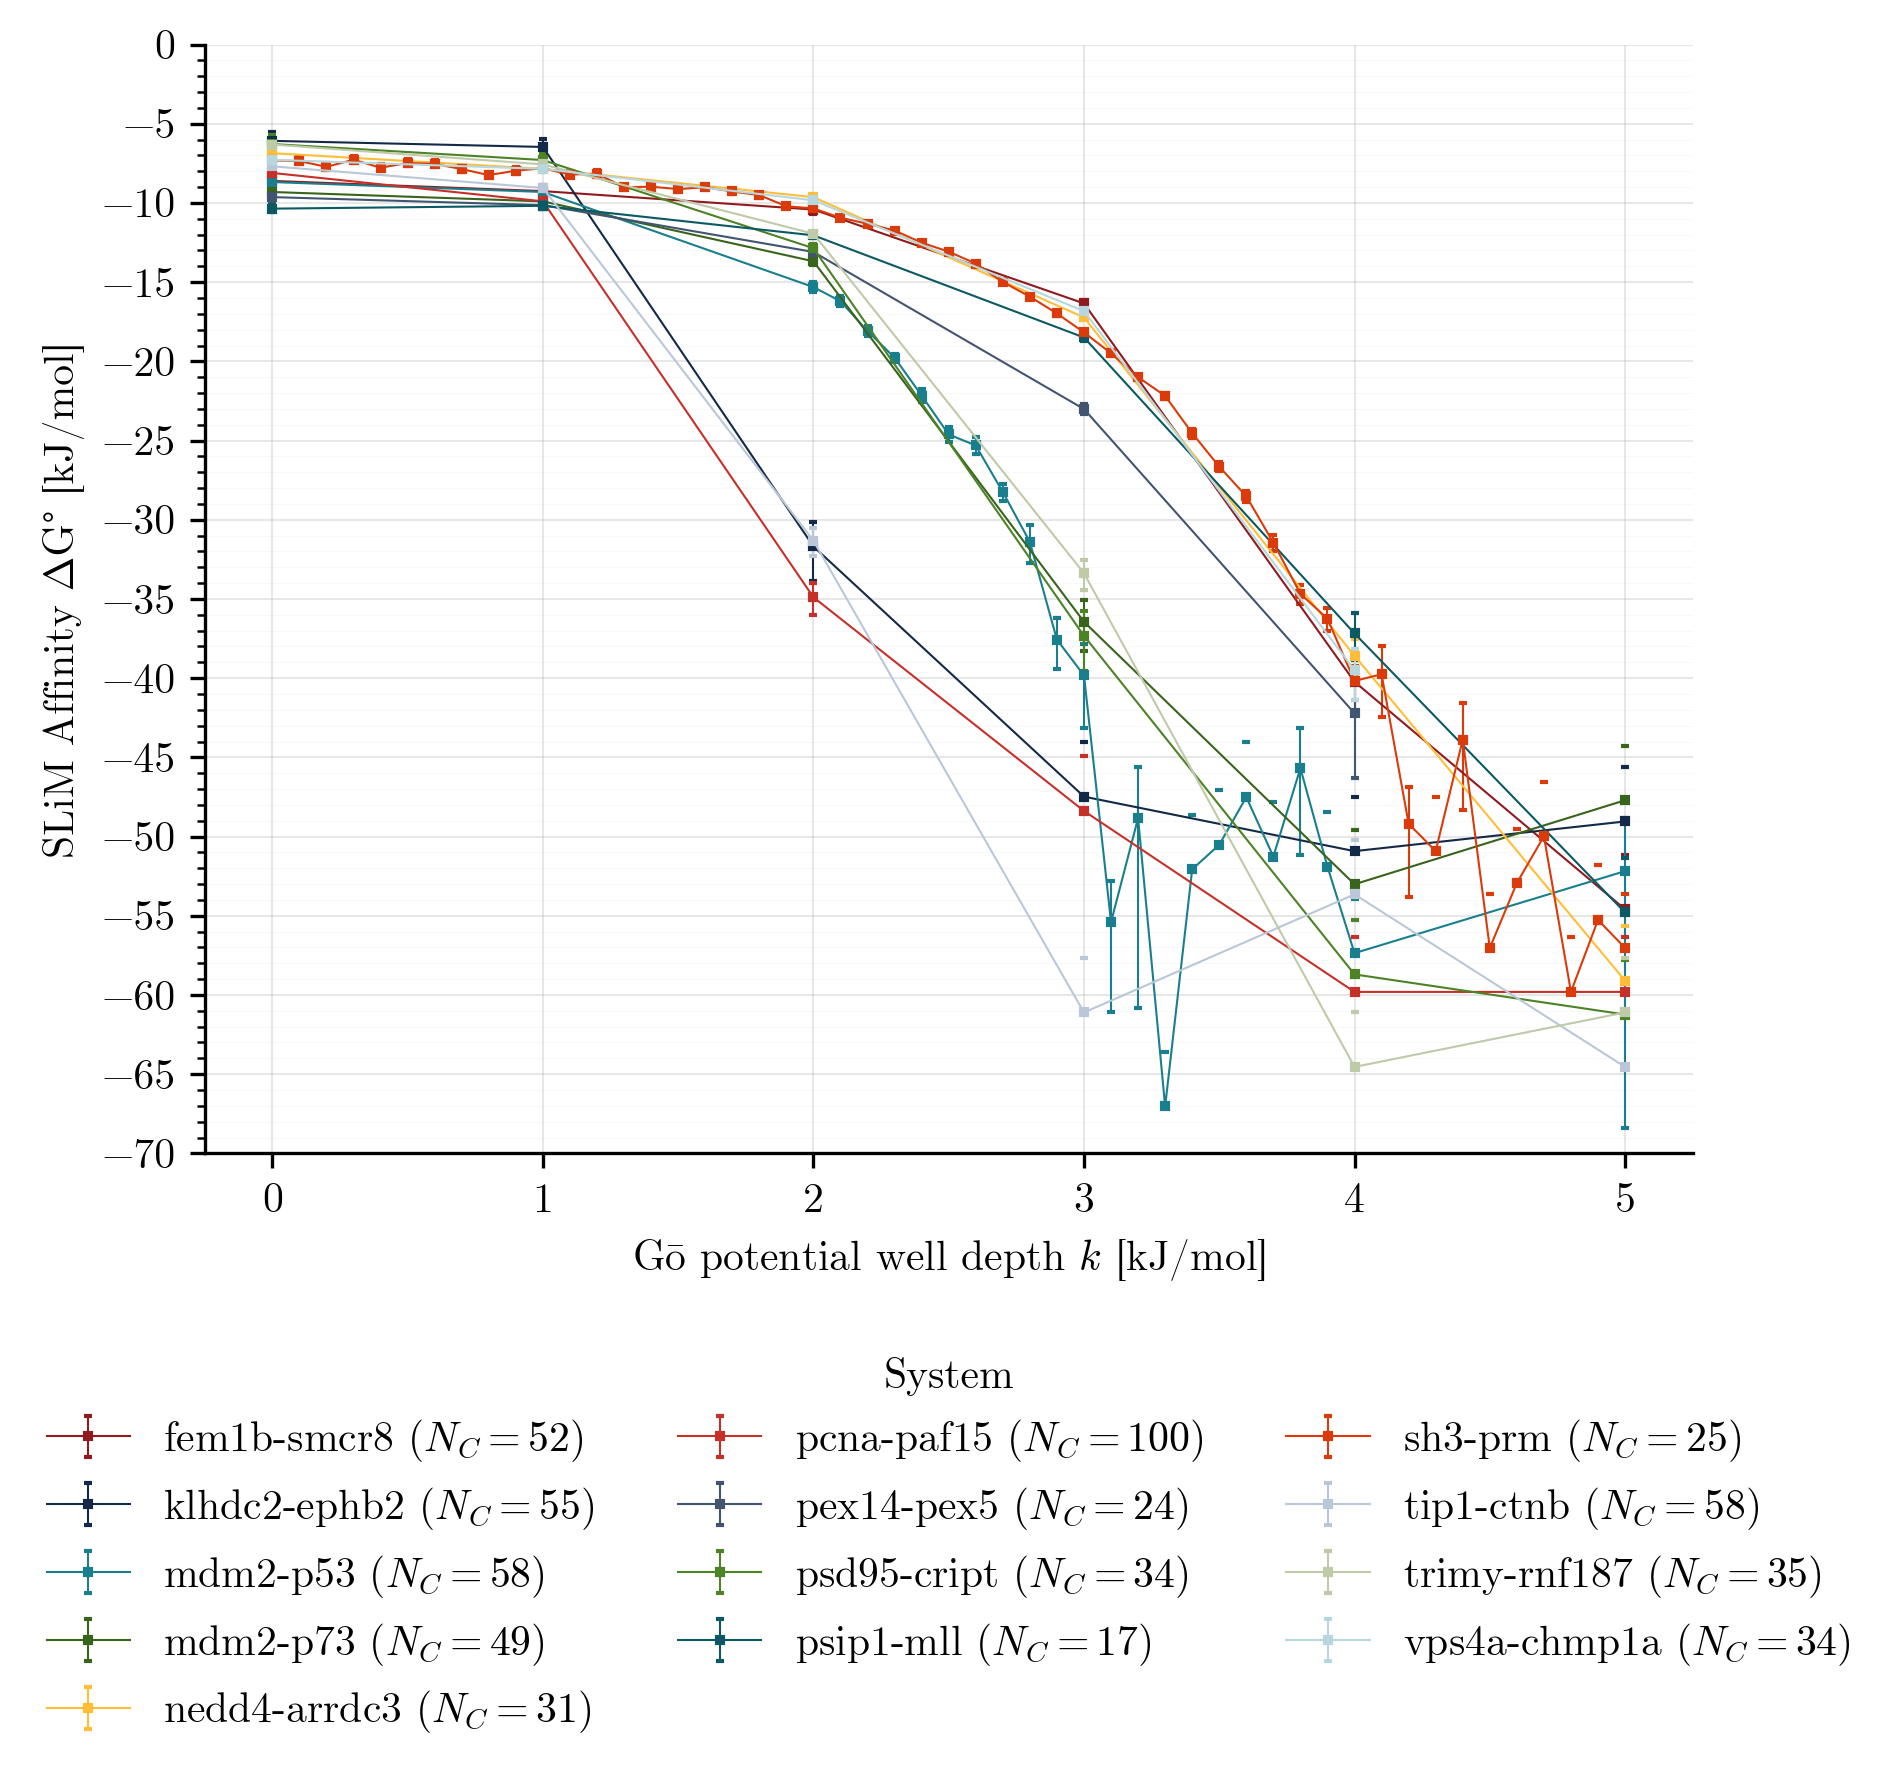

In [3]:
for system, subset in results.groupby('System'):
    subset = subset.dropna()
    subset = subset[~(subset == np.inf).any(axis=1)]
    dG_err = np.stack([subset['dG'] - subset['dG-1SEM'], subset['dG+1SEM'] - subset['dG']])
    plt.errorbar(
        x = subset['k'], y = subset['dG'], yerr = dG_err,
        ms=1.5, capsize=1, elinewidth=0.5, linewidth=0.5, fmt = '-s', 
        label=f"{system} ($N_C={subset.N_C.mean():.0f}$)"
    )
plt.ylabel('SLiM Affinity ΔG° [kJ/mol]')
plt.xlabel('Gō potential well depth $k$ [kJ/mol]')
ylim = plt.ylim(-70,0)
plt.yticks(np.arange(ylim[0],ylim[1]+.1,5),minor=False)
plt.yticks(np.arange(ylim[0],ylim[1]+.1,1),minor=True)
plt.grid(which='major', alpha=0.3, linewidth=0.5)
plt.grid(which='minor', alpha=0.1, linewidth=0.2)
plt.legend(frameon=False, ncol=3, title="System", loc='upper center', bbox_to_anchor=(0.5,-0.15))


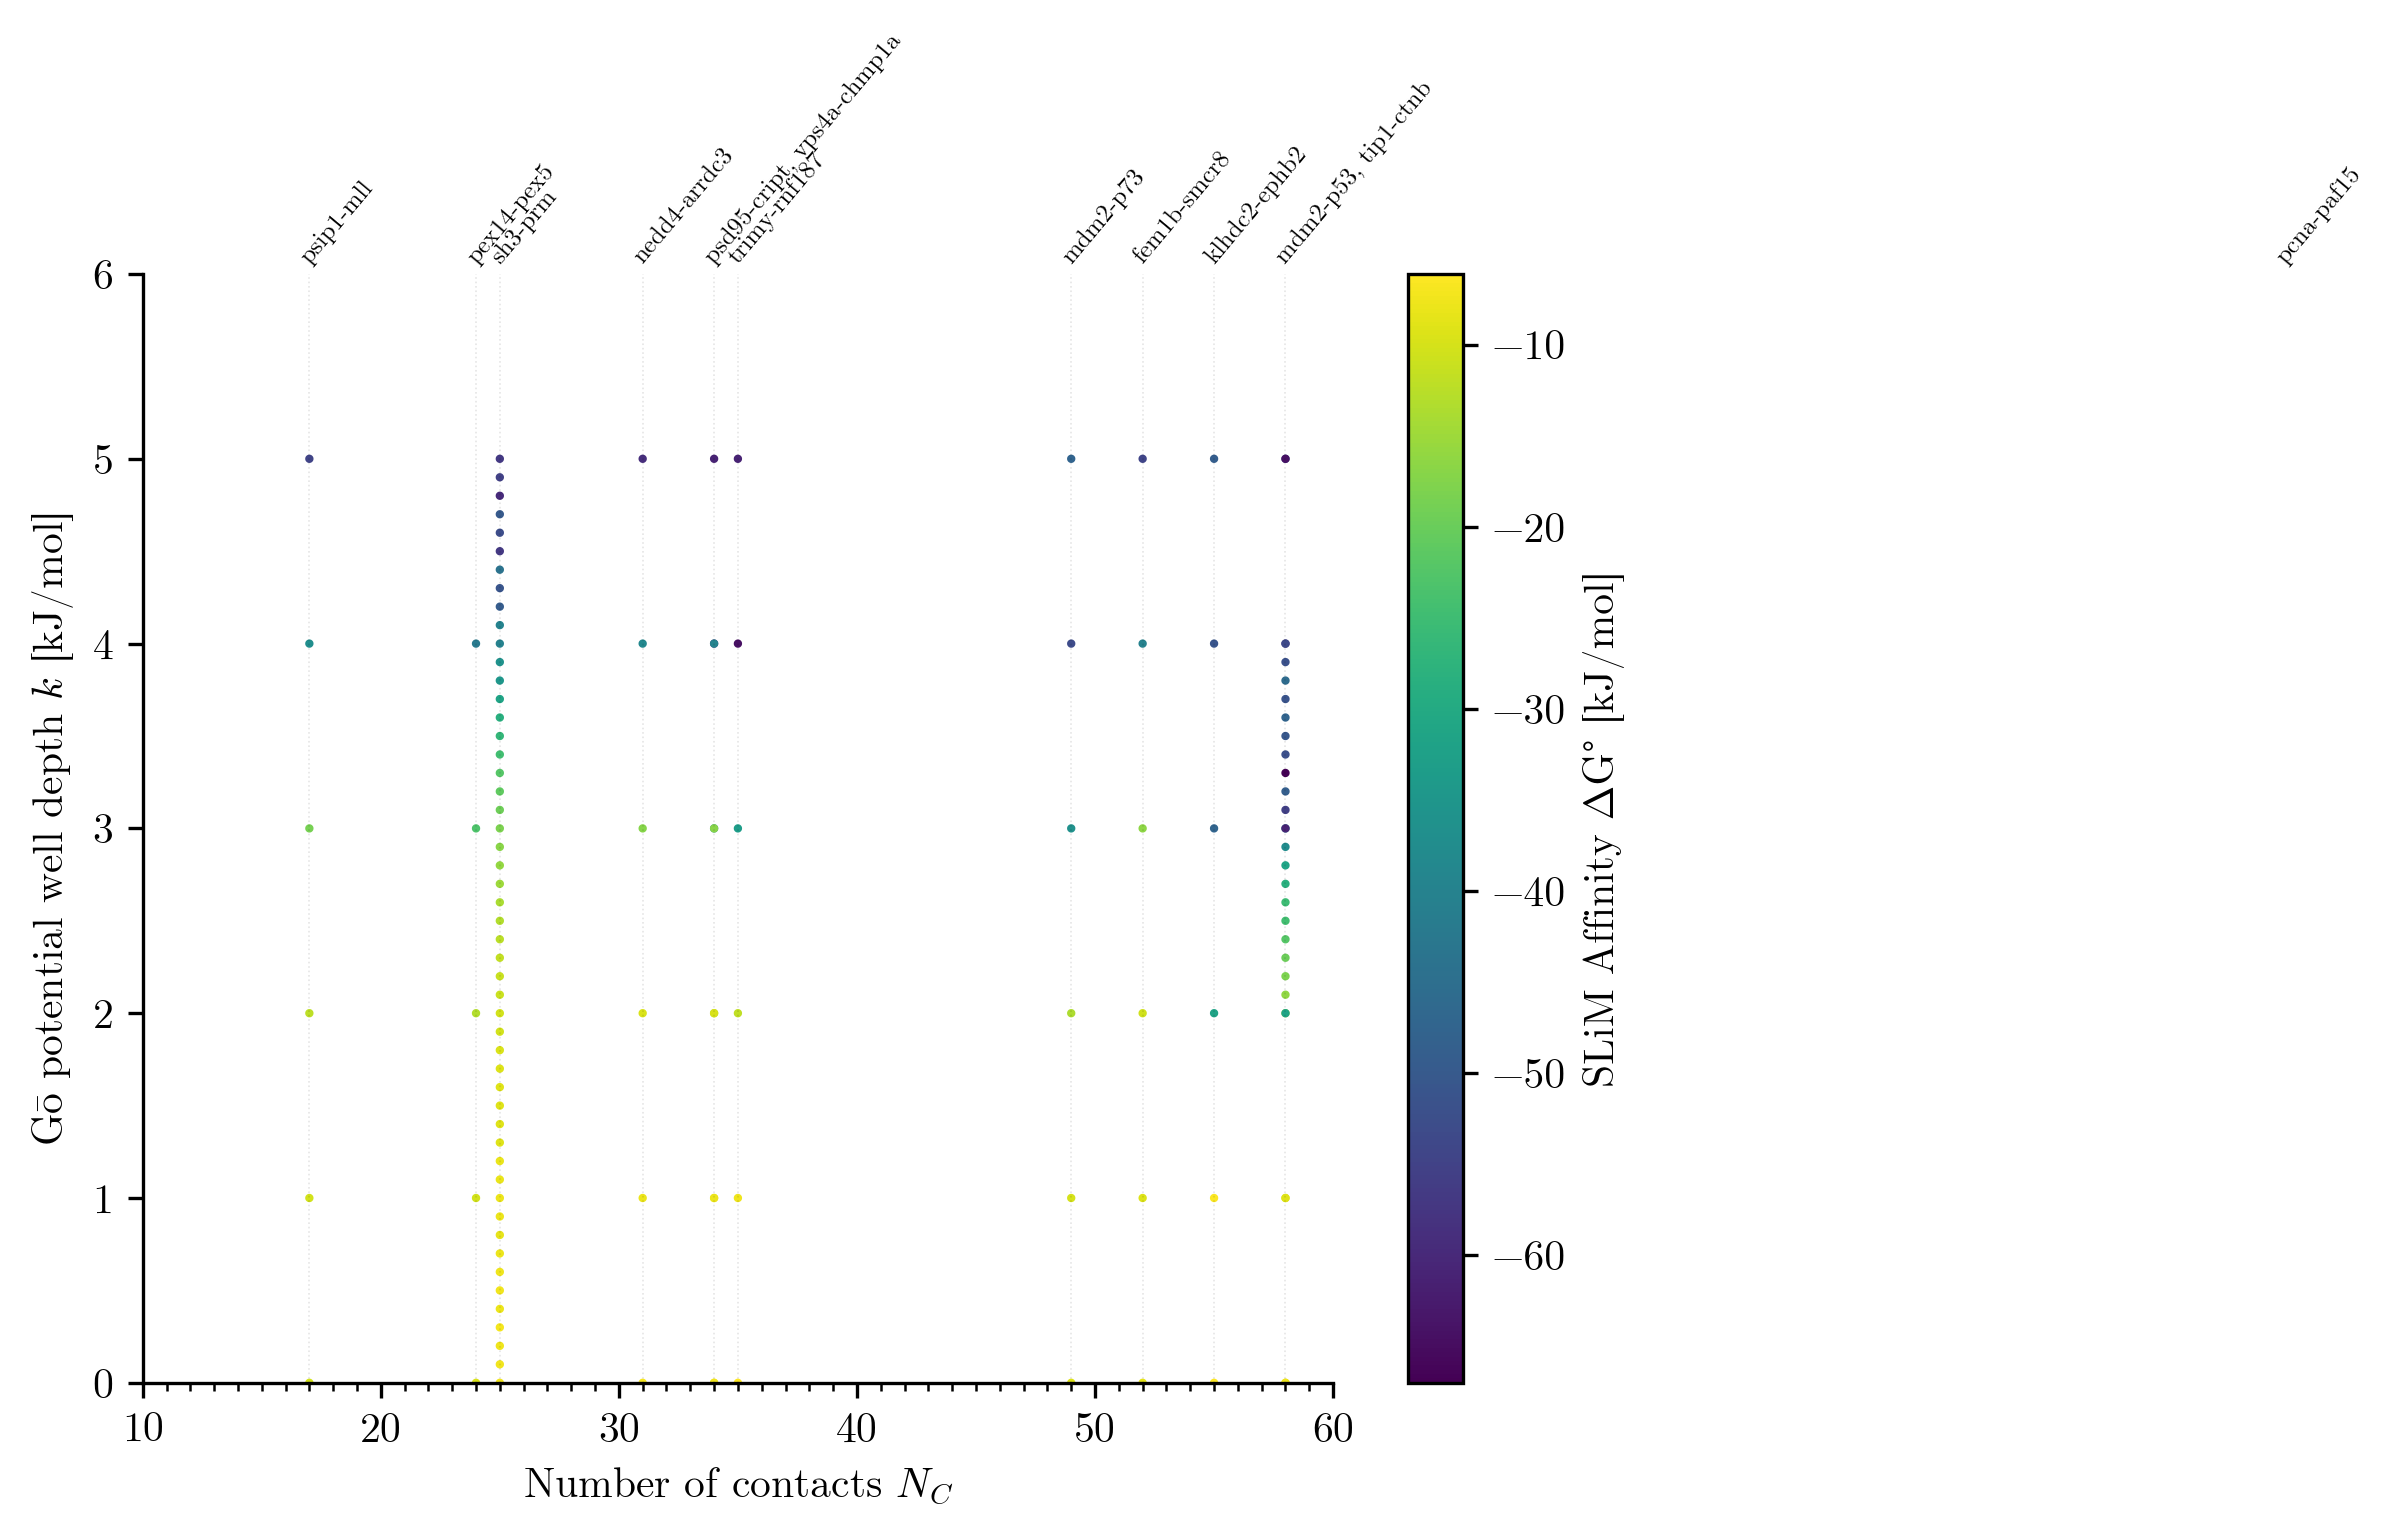

In [4]:
plt.scatter(
    x=results['N_C'],
    y=results['k'],
    c=results['dG']
)
ylim = plt.ylim(0,6)
for N_C, subset in results.groupby('N_C'):
    systems = subset['System'].drop_duplicates()
    plt.vlines(N_C, ylim[0], ylim[1], linewidth=0.4, color='k', alpha=0.1, linestyles='dotted')
    plt.text(N_C, ylim[1]+0.05, ', '.join(systems), rotation=50, fontsize=6, rotation_mode='anchor')
xlim = plt.xlim(10,60)
plt.xticks(np.arange(xlim[0], xlim[1]+1,1), minor=True)
plt.xlabel("Number of contacts $N_C$")
plt.ylabel("Gō potential well depth $k$ [kJ/mol]")
plt.colorbar(label="SLiM Affinity ΔG° [kJ/mol]")